<a href="https://colab.research.google.com/github/naik-aarya/Mall-Customer-Segmentation/blob/main/Mall_Customer_Segmentation_using_Kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Mall Customer Segmentation using KMeans**

Data : https://drive.google.com/file/d/19OWW8DWJ5kz2fuKp9oVvkkHmyDQYI0jf/view?usp=sharing

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
data = pd.read_csv('Mall_Customers.csv')

In [ ]:
data

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [ ]:
data.shape

(200, 5)

In [ ]:
data.dtypes

,0
CustomerID,int64
Gender,object
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64


In [ ]:
data.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [ ]:
# drop CustomerID
data.drop(columns='CustomerID',inplace=True)

In [ ]:
# check for missing values
data.isnull().sum()

,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [ ]:
# check for duplicates
data.duplicated().sum()

np.int64(0)

# **EDA**

<Axes: xlabel='Gender', ylabel='Annual Income (k$)'>

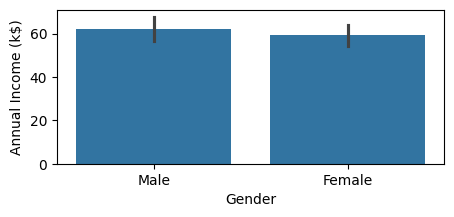

In [ ]:
# gender wise average annual income
plt.figure(figsize=(5,2))
sns.barplot(data,x='Gender',y='Annual Income (k$)')

<Axes: xlabel='Gender', ylabel='Spending Score (1-100)'>

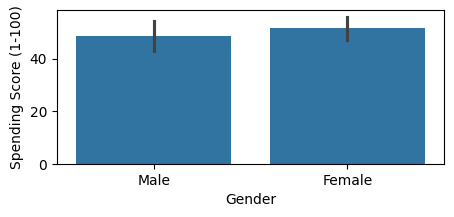

In [ ]:
# gender wise Spending Score (1-100)
plt.figure(figsize=(5,2))
sns.barplot(data,x='Gender',y='Spending Score (1-100)')

<Axes: xlabel='Age', ylabel='Annual Income (k$)'>

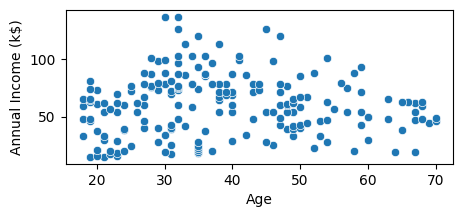

In [ ]:
# age v/s average annual income
plt.figure(figsize=(5,2))
sns.scatterplot(data,x='Age',y='Annual Income (k$)')

<Axes: xlabel='Age', ylabel='Spending Score (1-100)'>

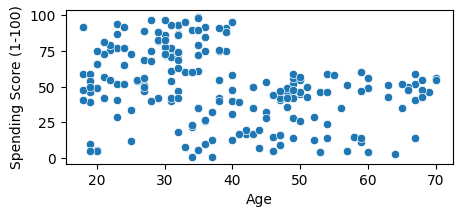

In [ ]:
# age v/s Spending Score (1-100)
plt.figure(figsize=(5,2))
sns.scatterplot(data,x='Age',y='Spending Score (1-100)')

<Axes: xlabel='Annual Income (k$)', ylabel='Spending Score (1-100)'>

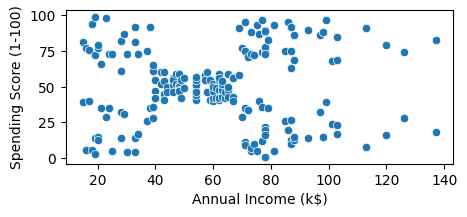

In [ ]:
# average annual income v/s Spending Score (1-100)
plt.figure(figsize=(5,2))
sns.scatterplot(data,x='Annual Income (k$)',y='Spending Score (1-100)')

**Encoding for Gender**

In [ ]:
df = data.copy()

In [ ]:
data = pd.get_dummies(data , columns=['Gender'],dtype='int')
data

,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male
0,19,15,39,0,1
1,21,15,81,0,1
2,20,16,6,1,0
3,23,16,77,1,0
4,31,17,40,1,0
...,...,...,...,...,...
195,35,120,79,1,0
196,45,126,28,1,0
197,32,126,74,0,1
198,32,137,18,0,1


**Scaling for Age	Annual Income (k$)	Spending Score (1-100)**

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data[['Age']]= scaler.fit_transform(data[['Age']])
data[['Annual Income (k$)']]= scaler.fit_transform(data[['Annual Income (k$)']])
data[['Spending Score (1-100)']]= scaler.fit_transform(data[['Spending Score (1-100)']])


# Kmeans model building

In [ ]:
from sklearn.cluster import KMeans
model = KMeans(n_clusters=8)
model.fit(data)

KMeans()

In [ ]:
df['clusters']=model.predict(data)
df

,Gender,Age,Annual Income (k$),Spending Score (1-100),clusters
0,Male,19,15,39,4
1,Male,21,15,81,4
2,Female,20,16,6,3
3,Female,23,16,77,4
4,Female,31,17,40,3
...,...,...,...,...,...
195,Female,35,120,79,1
196,Female,45,126,28,0
197,Male,32,126,74,5
198,Male,32,137,18,0


In [ ]:
df['clusters'].unique()

array([4, 3, 6, 2, 7, 5, 1, 0], dtype=int32)

In [ ]:
# use silhouette
from sklearn.metrics import silhouette_score
labels = model.predict(data)
silhouette_score(data,labels)

np.float64(0.3263780643996867)

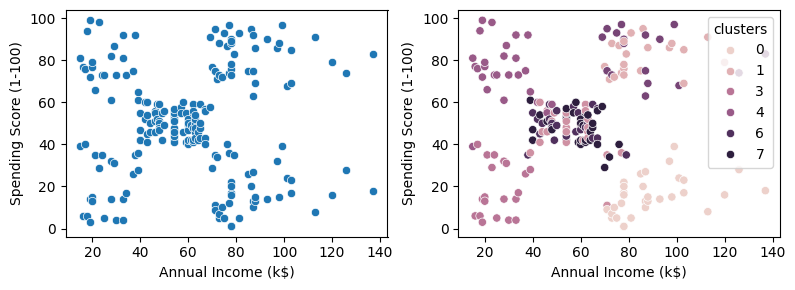

In [ ]:
fig,ax = plt.subplots(1,2,figsize=(8,3))
sns.scatterplot(df,x='Annual Income (k$)',y='Spending Score (1-100)',ax=ax[0])
sns.scatterplot(df,x='Annual Income (k$)',y='Spending Score (1-100)',hue='clusters',ax=ax[1])
plt.tight_layout()

# Elbow Method

Its used find optimal values for K .

1. It starts with possible values of k=2,3,4,5,...
2. For every K value we implement Kmean and we find wcss value for each k
3. Wcss: within clustered sum of squares

Sum of squared distance between observation and centroid.
  
  wcss = summation(xi-ci)^2

  xi--> observation

  ci--> cluster center

4. Plot graph of Wcss v/s k value

5. Select k values where there is a sudden decline in value(elbow point)

In [ ]:
wcss=[]
for k in range(2,11):
  model = KMeans(n_clusters=k)
  model.fit(data)
  wcss.append(model.inertia_)

In [ ]:
wcss

[487.65863415711783,
 394.37337048316306,
 303.33397722404874,
 268.7833007695962,
 248.9266510260503,
 219.55655672287529,
 191.1687979333359,
 167.88983690566874,
 165.7199660310268]

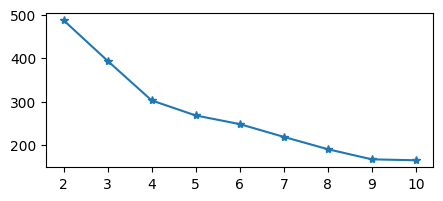

In [ ]:
plt.figure(figsize=(5,2))
plt.plot(range(2,11),wcss,marker='*')

k=4 is the optimal value from this method.

In [ ]:
# train model with k=4
model = KMeans(n_clusters=4)
model.fit(data)
labels = model.predict(data)

In [ ]:
silhouette_score(data,labels)

np.float64(0.3186027422464204)

In [ ]:
df['cluster1']=model.predict(data)

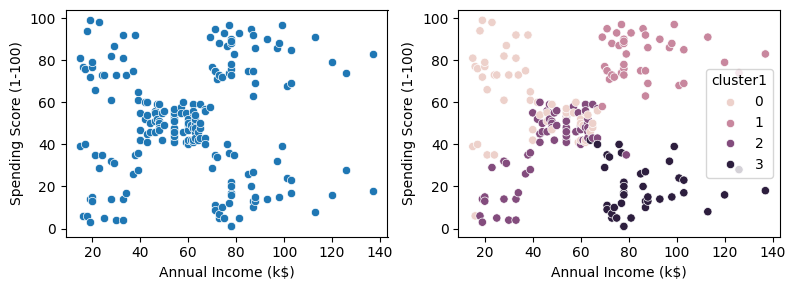

In [ ]:
fig,ax = plt.subplots(1,2,figsize=(8,3))
sns.scatterplot(df,x='Annual Income (k$)',y='Spending Score (1-100)',ax=ax[0])
sns.scatterplot(df,x='Annual Income (k$)',y='Spending Score (1-100)',hue='cluster1',ax=ax[1])
plt.tight_layout()